In [2]:
from astropy.io import fits
from astropy.visualization import ZScaleInterval
import astropy.coordinates as coord
from astropy.wcs import WCS
import astropy.units as u
from astroquery.vizier import Vizier
from scipy.optimize import curve_fit
from scipy.spatial.distance import cdist
from scipy.ndimage import label
from glob import glob
import cmastro
import pandas as pd
import os
import matplotlib.pyplot as plt
import numpy as np
import pprint

plt.rcParams['image.origin'] = 'lower'

Useful functions for working with .fits files

In [3]:
def read_file(filename):
    image = fits.open("{f}".format(f=filename))[0].data.astype(int)
    return image

def header(filename):
    header = fits.open("{f}".format(f=filename))[0].header
    return header

def view(image, title, c = 'gray'):
    fig = plt.figure(figsize=(24, 12))
    vmin, vmax = ZScaleInterval().get_limits(image)
    plt.imshow(image, vmin=vmin, vmax=vmax, origin='lower', cmap=c)
    plt.title(title)
    plt.colorbar()
    plt.show()

def get_and_sort_files(folder, extension = 'fts'):
    # Get all .fts files
    files = [y for x in os.walk(folder) for y in glob(os.path.join(x[0], '*.' + extension))]

    # Pick out types of images and sort
    asteroid_files = [f for f in files if "26Proserpina-" in f]
    ast_headers = [header(f) for f in asteroid_files]
    flat_files = [f for f in files if "Flat" in f]
    dark_files = [f for f in files if "Dark" in f]
    bias_files = [f for f in files if "Bias" in f]
    asteroid_files.sort()
    flat_files.sort() 
    dark_files.sort() 
    bias_files.sort()
    return asteroid_files, ast_headers, flat_files, dark_files, bias_files   

**1. Get images categorized by date and type**

In [4]:
# 4 obs nights, 3 astroid images each
folder = "26Proserpina/"
observations = ["20120119", "20120120", "20120122", "20120125"]

# Images paths for each obs night
asteroid1, headers1, flats1, darks1, biases1 = get_and_sort_files(folder + observations[0])
asteroid2, headers2, flats2, darks2, biases2 = get_and_sort_files(folder + observations[1])
asteroid3, headers3, flats3, darks3, biases3 = get_and_sort_files(folder + observations[2])
asteroid4, headers4, flats4, darks4, biases4 = get_and_sort_files(folder + observations[3])

**2. Clean the images**

View all exposures and temperatures

In [5]:
flats = flats1 + flats2 + flats3 + flats4
darks = darks1 + darks2 + darks3 + darks4
biases = biases1 + biases2 + biases3 + biases4
astroids = asteroid1 + asteroid2 + asteroid3 + asteroid4
headers = headers1 + headers2 + headers3 + headers4
for asteroid in astroids:
    exp = header(asteroid)["EXPOSURE"]
    date = header(asteroid)["DATE-OBS"]
    temp = header(asteroid)["CCD-TEMP"]
    print("ASTEROID {d} - Exposure: {e}s, Temp: {t}".format(d=date, e=exp, t=temp))
print("-----------------------------")
for flat in flats:
    exp = header(flat)["EXPOSURE"]
    date = header(flat)["DATE-OBS"]
    temp = header(flat)["CCD-TEMP"]
    print("FLAT {d} - Exposure: {e}s, Temp: {t}".format(d=date, e=exp, t=temp))
print("-----------------------------")
for dark in darks:
    exp = header(dark)["EXPOSURE"]
    date = header(dark)["DATE-OBS"]
    temp = header(dark)["CCD-TEMP"]
    print("DARK {d} - Exposure: {e}s, Temp: {t}".format(d=date, e=exp, t=temp))
print("-----------------------------")
for bias in biases:
    exp = header(bias)["EXPOSURE"]
    date = header(bias)["DATE-OBS"]
    temp = header(bias)["CCD-TEMP"]
    print("BIAS {d} - Exposure: {e}s, Temp: {t}".format(d=date, e=exp, t=temp))

ASTEROID 2012-01-20T07:27:54 - Exposure: 60.0s, Temp: -25.218294750000005
ASTEROID 2012-01-20T07:29:21 - Exposure: 60.0s, Temp: -25.108281000000005
ASTEROID 2012-01-20T07:30:48 - Exposure: 60.0s, Temp: -25.117710750000004
ASTEROID 2012-01-21T07:39:37 - Exposure: 60.0s, Temp: -25.114567500000007
ASTEROID 2012-01-21T07:41:03 - Exposure: 60.0s, Temp: -25.023413250000004
ASTEROID 2012-01-21T07:42:29 - Exposure: 60.0s, Temp: -25.06113225
ASTEROID 2012-01-23T08:35:52 - Exposure: 60.0s, Temp: -25.183719
ASTEROID 2012-01-23T08:37:18 - Exposure: 60.0s, Temp: -25.14914325
ASTEROID 2012-01-23T08:38:44 - Exposure: 60.0s, Temp: -25.139713500000006
ASTEROID 2012-01-26T05:05:05 - Exposure: 60.0s, Temp: -25.123997250000002
ASTEROID 2012-01-26T05:06:19 - Exposure: 60.0s, Temp: -25.070562000000002
ASTEROID 2012-01-26T05:07:33 - Exposure: 60.0s, Temp: -25.136570250000005
-----------------------------
FLAT 2012-01-20T00:44:14 - Exposure: 1.75s, Temp: -4.702302
FLAT 2012-01-20T00:44:28 - Exposure: 2.07s, T

For the first, night the temperature controller was apparently off when taking the darks, so master dark will be from only 2/3 nights.

In [6]:
flats = [flat for flat in flats if header(flat)["CCD-Temp"] < -15]

We only want 60s darks to match our sky images. Now to create median images to use for cleaning

In [7]:
darks60 = [dark for dark in darks if np.abs(header(dark)["EXPOSURE"] - 60) <= 1]
print(darks60)

['26Proserpina/20120119/Calibration/Dark-S001-R003-C001-B2.fts', '26Proserpina/20120119/Calibration/Dark-S001-R003-C002-B2.fts', '26Proserpina/20120119/Calibration/Dark-S001-R003-C003-B2.fts', '26Proserpina/20120119/Calibration/Dark-S001-R003-C004-B2.fts', '26Proserpina/20120119/Calibration/Dark-S001-R003-C005-B2.fts', '26Proserpina/20120120/Calibration/Dark-S001-R003-C001-B2.fts', '26Proserpina/20120120/Calibration/Dark-S001-R003-C002-B2.fts', '26Proserpina/20120120/Calibration/Dark-S001-R003-C003-B2.fts', '26Proserpina/20120120/Calibration/Dark-S001-R003-C004-B2.fts', '26Proserpina/20120120/Calibration/Dark-S001-R003-C005-B2.fts', '26Proserpina/20120122/Calibration/Dark-S001-R003-C001-B2.fts', '26Proserpina/20120122/Calibration/Dark-S001-R003-C002-B2.fts', '26Proserpina/20120122/Calibration/Dark-S001-R003-C003-B2.fts', '26Proserpina/20120122/Calibration/Dark-S001-R003-C004-B2.fts', '26Proserpina/20120122/Calibration/Dark-S001-R003-C005-B2.fts', '26Proserpina/20120125/Calibration/Dark

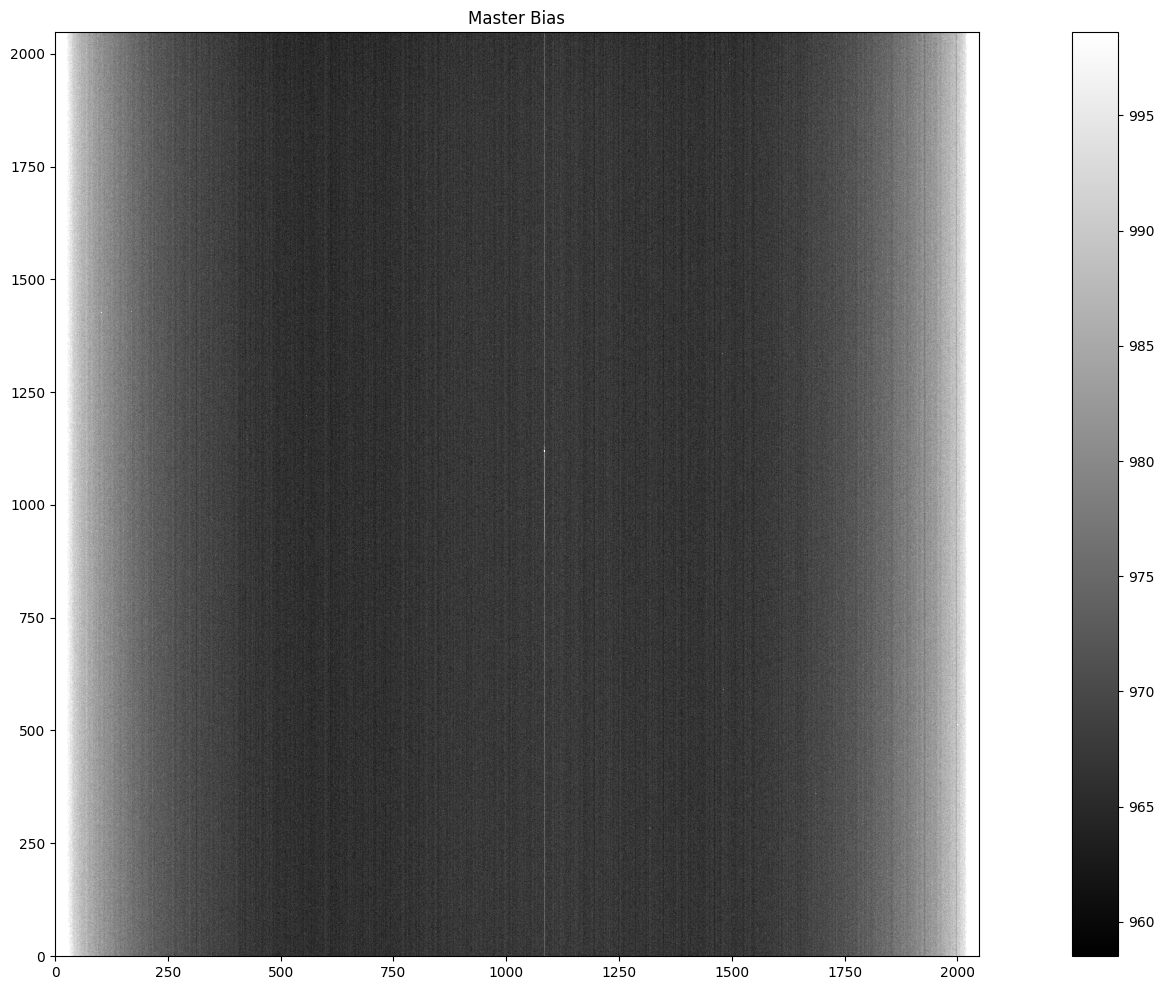

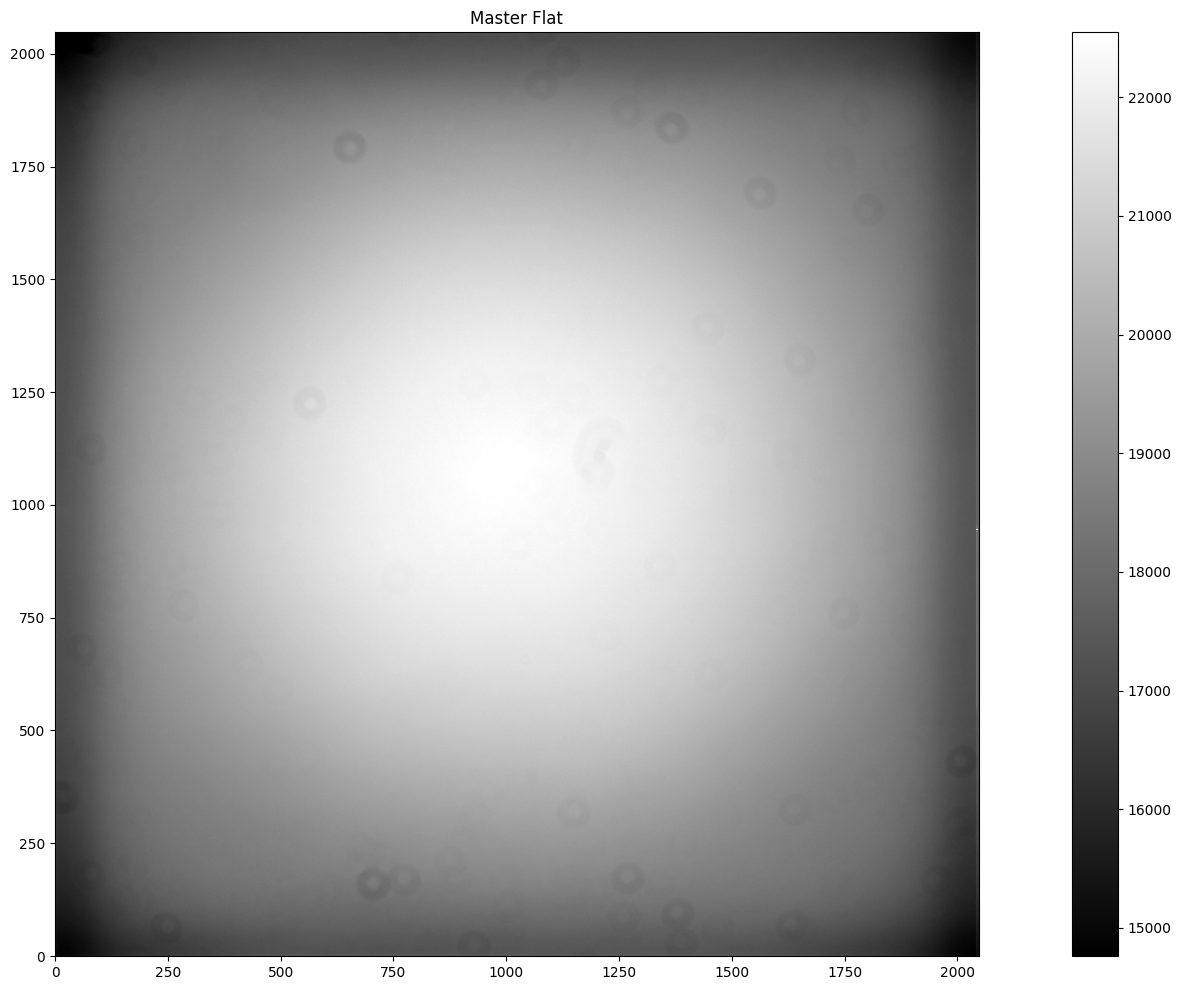

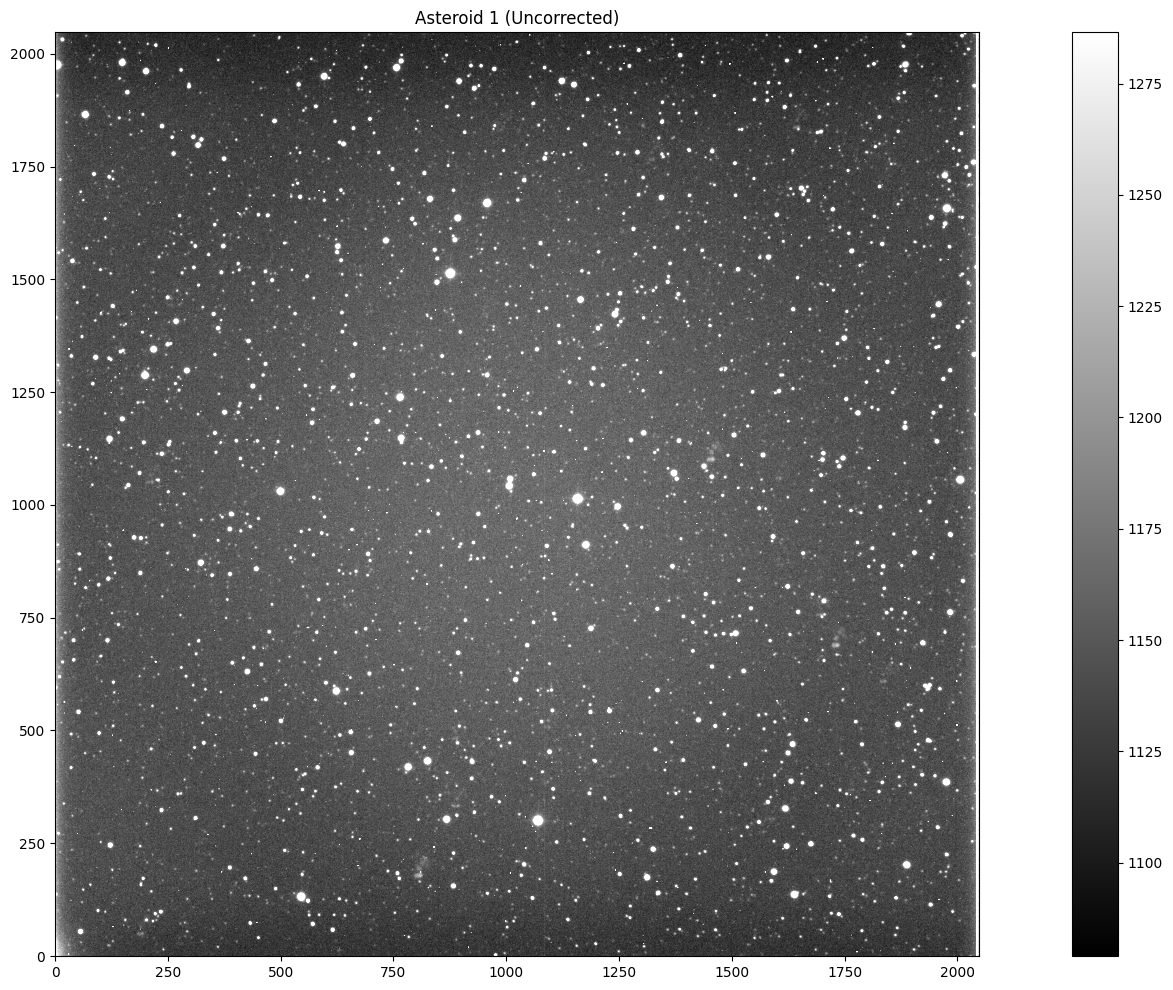

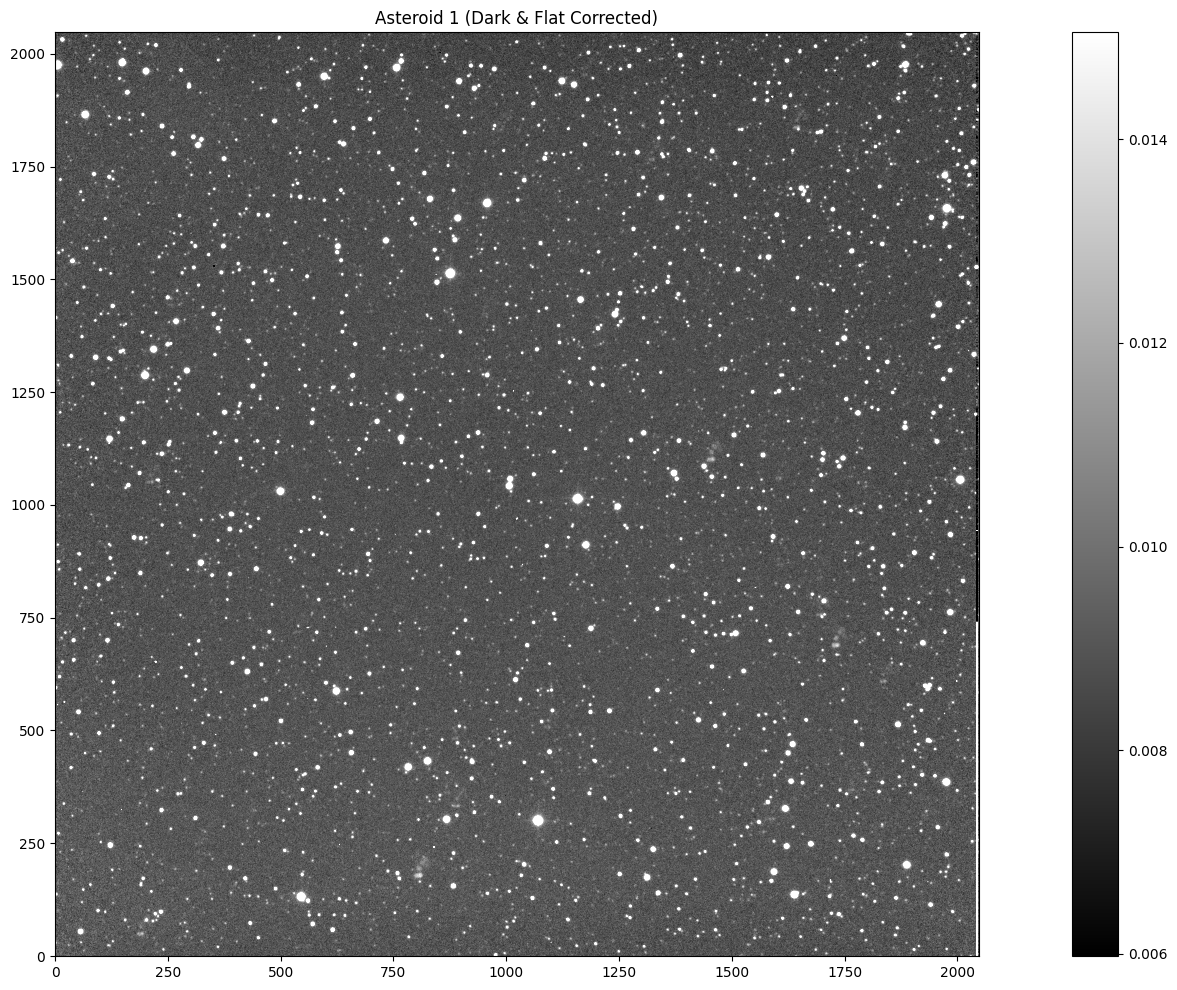

In [8]:
# Numpy arrays of images
all_astroid_np = np.array([read_file(f) for f in astroids])
all_biases_np = np.array([read_file(f) for f in biases])
all_dark60_np = np.array([read_file(f) for f in darks60])
all_flat_np = np.array([read_file(f) for f in flats])

# Flip science images
all_astroid_np = [all_astroid_np[::-1,::-1] for all_astroid_np in all_astroid_np]
# Median combine darks
master_dark = np.median(all_dark60_np, axis=0)
master_flat = np.median(all_flat_np, axis=0)
master_bias = np.median(all_biases_np, axis=0)

view(master_bias, "Master Bias")
view(master_flat, "Master Flat")

science_imgs = ((all_astroid_np - master_dark) / (master_flat))

view(all_astroid_np[0], "Asteroid 1 (Uncorrected)")
view(science_imgs[0], "Asteroid 1 (Dark & Flat Corrected)")

In [9]:

# for i, image in enumerate(science_imgs):
#     view(image, "Science Image Numer {i}".format(i=i), 'cma:lacerta')

**Crossmatching Stars**

Centroid Finding Algorithm

In [10]:

def star_gaussian(stars, image, plot=False):    
    centroids_x_coords = []
    centroids_y_coords = []
    failed_fittings = 0
    size = 10
    # 2d gaussian
    def gauss(xy, a, x0, y0, sigma_x, sigma_y, c):
        x, y = xy
        g = a*np.exp(-(x-x0)**2/(2*sigma_x**2) - (y-y0)**2/(2*sigma_y**2)) + c
        return g.ravel()

    for i in range(len(stars[0])):
        box = image[stars[0][i]-size:stars[0][i]+size, stars[1][i]-size:stars[1][i]+size]
        
        # Create coordinate matrices and flatten them for fitting
        xx, yy = np.meshgrid(np.arange(box.shape[1]), np.arange(box.shape[0])) 
        xx_flat = xx.ravel()
        yy_flat = yy.ravel()

        # Use centroid equation for initial guess
        x = np.sum(xx * box) / np.sum(box) 
        y = np.sum(yy * box) / np.sum(box) 

        # Fit Gaussian
        if len(yy_flat) != 0:
            try:
                initial_guess = (1,x,y,1,1,0)
                popt, pcov = curve_fit(gauss, (xx_flat, yy_flat), box.ravel(), p0=initial_guess)
                
                # get new centroid
                centroid_x, centroid_y = popt[1], popt[2]
                
                # put the coords back in the original context of the image
                x = stars[0][i] - size + x
                y = stars[1][i] - size + y
                centroid_x = stars[0][i] - size + centroid_x
                centroid_y = stars[1][i] - size + centroid_y
                # print(f"Inital Centroid: {x}, {y}")
                # print(f"Gaussian Centroid: {centroid_x}, {centroid_y}")
                
                # add centroids to list of coords
                centroids_x_coords.append(centroid_x)
                centroids_y_coords.append(centroid_y)
                
                
            except RuntimeError:
                failed_fittings += 1
                
    print(f"Couldn't fit {failed_fittings} stars")
    return centroids_x_coords, centroids_y_coords

def star_gaussian_single_coord(stars, image, plot=False): 
    size = 10
    # 2d gaussian
    def gauss(xy, a, x0, y0, sigma_x, sigma_y, c):
        x, y = xy
        g = a*np.exp(-(x-x0)**2/(2*sigma_x**2) - (y-y0)**2/(2*sigma_y**2)) + c
        return g.ravel()
    
    box = image[int(stars[0])-size:int(stars[0])+size, int(stars[1])-size:int(stars[1])+size]
    xx, yy = np.meshgrid(np.arange(box.shape[1]), np.arange(box.shape[0])) 
    xx_flat = xx.ravel()
    yy_flat = yy.ravel()

    # Use centroid equation for initial guess
    x = np.sum(xx * box) / np.sum(box) 
    y = np.sum(yy * box) / np.sum(box) 

    # Fit Gaussian
    if len(yy_flat) != 0:
        initial_guess = (1,x,y,1,1,0)
        popt, pcov = curve_fit(gauss, (xx_flat, yy_flat), box.ravel(), p0=initial_guess)
        
        # get new centroid
        centroid_x, centroid_y = popt[1], popt[2]
        
        # put the coords back in the original context of the image
        x = stars[0] - size + x
        y = stars[1] - size + y
        centroid_x = stars[0] - size + centroid_x
        centroid_y = stars[1] - size + centroid_y
        # print(f"Inital Centroid: {x}, {y}")
        # print(f"Gaussian Centroid: {centroid_x}, {centroid_y}")
        
        # add centroids to list of coords
        return centroid_x, centroid_y

        

Applying to all stars

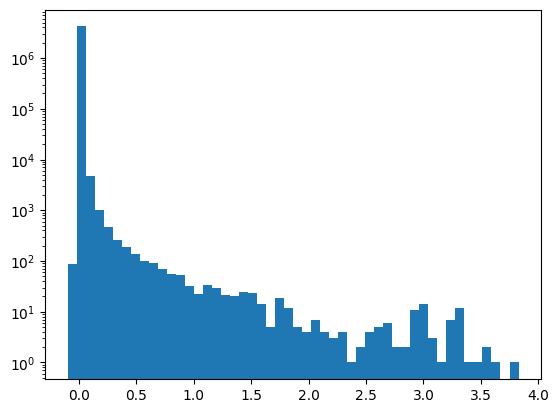

In [11]:
plt.hist(science_imgs[0].flatten(), bins=50)
plt.yscale('log')

Found 5678 stars


/tmp/ipykernel_193680/3371251581.py:21: RuntimeWarning: invalid value encountered in scalar divide
  x = np.sum(xx * box) / np.sum(box)
/tmp/ipykernel_193680/3371251581.py:22: RuntimeWarning: invalid value encountered in scalar divide
  y = np.sum(yy * box) / np.sum(box)
/tmp/ipykernel_193680/3371251581.py:28: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = curve_fit(gauss, (xx_flat, yy_flat), box.ravel(), p0=initial_guess)


Couldn't fit 223 stars


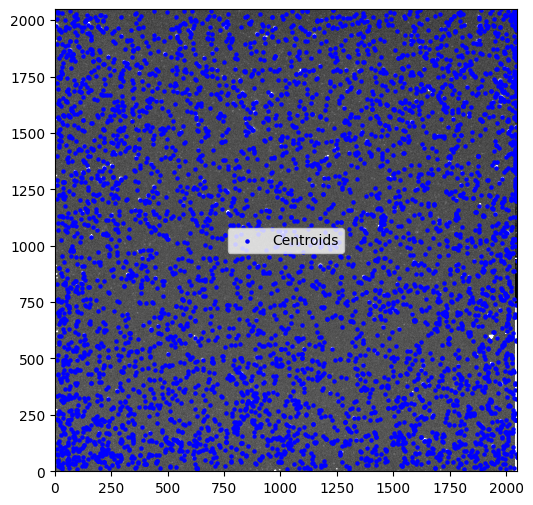

In [12]:
threshold = 0.0125
stars_y = []
stars_x = []
# Find parts of img where intensity > threshold
binary_img = np.where(science_imgs[0] > threshold, 1, 0)

# Assign each star region a different integer
star_labels, num_stars = label(binary_img)
print(f"Found {num_stars} stars")

# Loop through each region and pick a single point to feed the centroider.
for i in range(1,num_stars+1):
    region_coords = np.where(star_labels == i)
    # Use middle point in each region
    middle_x = np.mean(region_coords[0]).astype(int)
    middle_y = np.mean(region_coords[1]).astype(int) 
    stars_x.append(middle_x)
    stars_y.append(middle_y)
    
centroid_x, centroid_y = star_gaussian([stars_x, stars_y], science_imgs[0])
centroid_catalog = pd.DataFrame({'centroid_x': centroid_x, 'centroid_y': centroid_y})

fig = plt.figure(figsize=(12, 6))
vmin, vmax = ZScaleInterval().get_limits(science_imgs[0])
plt.imshow(science_imgs[0], vmin=vmin, vmax=vmax, origin='lower', cmap='gray')
plt.scatter(centroid_y,centroid_x, marker='.', color='blue', label="Centroids", s=20)
#plt.scatter(stars_y, stars_x, marker='.', color='red', label="Thresholded Stars", s=20)
plt.xlim(0,2048)
plt.ylim(0,2048)
plt.legend()

Getting USNO coordinates

Converting USNO RA/DEC positions into pixel coordinates

05h24m08.28107592s +26d58m30.98376984s


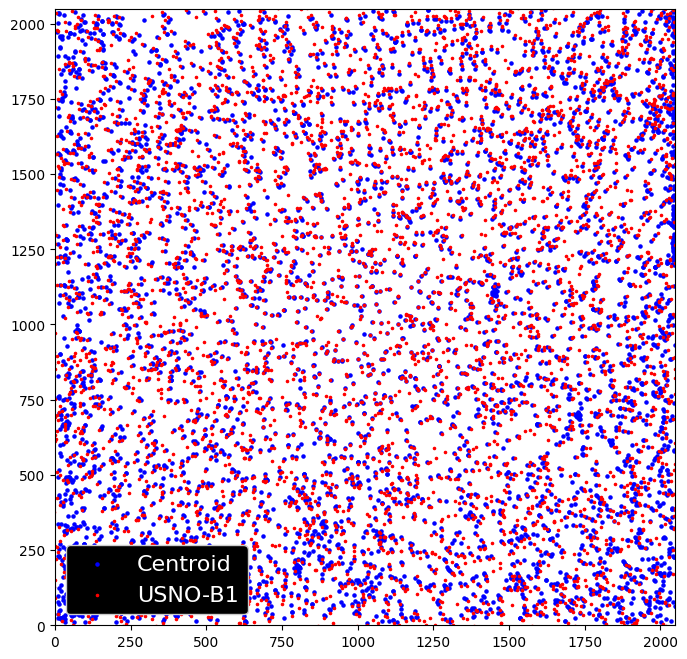

Num centroids 5272
Num USNO 6671


In [13]:
# Get center of field and query USNO-B1
cof = coord.SkyCoord(header(astroids[0])['CRVAL1'], header(astroids[0])['CRVAL2'], unit=(u.deg, u.deg), equinox='J2000')
print(cof.to_string('hmsdms'))
fov = 42*u.arcmin
Vizier.ROW_LIMIT = -1
usno = Vizier.query_region(cof, width=fov, catalog='USNO-B1')[0].to_pandas()

# plt.scatter(usno['RAJ2000'], usno['DEJ2000'], s=1, color='red')
# plt.xlabel('RA (deg)')
# plt.ylabel('Dec (deg)')
# plt.show()

mag_limit = 18.8
usno_reduced = usno[usno['R2mag'] < mag_limit].reset_index(drop=True)

# plt.scatter(usno_reduced['RAJ2000'], usno_reduced['DEJ2000'], s=2, color='red')
# plt.xlabel('RA (deg)')
# plt.ylabel('Dec (deg)')
# plt.show()

def initial_transform(usno_coords, focal_length, pixel_size, rotation, center_of_field, x_0, y_0):
    
    alpha = np.deg2rad(usno_coords[:,0])
    delta = np.deg2rad(usno_coords[:,1])
    alpha_0 = center_of_field.ra.rad
    delta_0 = center_of_field.dec.rad
    
    # Project to X and Y
    X = -(np.cos(delta)*np.sin(alpha - alpha_0))/((np.cos(delta_0))*np.cos(delta)*np.cos(alpha-alpha_0)+np.sin(delta)*np.sin(delta_0))
    Y = -(np.sin(delta_0)*np.cos(delta)*np.cos(alpha-alpha_0)-np.cos(delta_0)*np.sin(delta))/(np.cos(delta_0)*np.cos(delta)*np.cos(alpha-alpha_0)+np.sin(delta)*np.sin(delta_0))
    
    x_offset = x_0
    y_offset = y_0
    
    # # Convert to pixels
    # x = focal_length*(X/pixel_size) + x_offset
    # y = focal_length*(Y/pixel_size) + y_offset
    
    x = (focal_length/pixel_size)*(X*np.cos(rotation) - Y*np.sin(rotation)) + x_offset
    y = (focal_length/pixel_size)*(X*np.sin(rotation) + Y*np.cos(rotation)) + y_offset
    return x, y

pixel_size = 0.018 # mm
image_shape = (2048, 2048) # after binning
focal_length = 3454 # mm F/6.8
rotation = np.deg2rad(-89)
x_offset = 1024
y_offset = 1024
usno_stars = np.column_stack((usno_reduced['RAJ2000'], usno_reduced['DEJ2000']))

approximate_x, approximate_y = initial_transform(usno_stars, focal_length, pixel_size, rotation, cof, x_offset, y_offset)
usno_reduced['approx_x'] = approximate_x
usno_reduced['approx_y'] = approximate_y

fig = plt.figure(figsize=(8, 8))
vmin, vmax = ZScaleInterval().get_limits(science_imgs[0])
#plt.imshow(science_imgs[0], cmap='gray', origin='lower', vmin=vmin, vmax=vmax)
plt.scatter(centroid_y, centroid_x, marker='.' , color ='blue', s=20, label='Centroid')
plt.scatter(usno_reduced['approx_y'], usno_reduced['approx_x'], marker='.', s=10, color='red', label='USNO-B1')
plt.xlim(0,2048)
plt.ylim(0,2048)
plt.legend(loc='lower left', fontsize = 16, labelcolor='white', facecolor='black', framealpha = 1)
plt.show()

print("Num centroids" , len(centroid_x))
print("Num USNO" , len(usno_reduced['approx_x']))


In [14]:
# Returns nearest star 
def distance(centroid_catalog, catalog):    # Check distances between each centroid and all stars in catalog
    distances = cdist(centroid_catalog[['centroid_x', 'centroid_y']], catalog[['approx_x', 'approx_y']], metric='euclidean')
    nearest_star_indices = []
    nearest_star_distances = []
    # Find indexes of shortest distances for each centroid
    for i in range(len(distances)):
        nearest_star_indices.append(np.argmin(distances[i]))
        nearest_star_distances.append(np.min(distances[i]))
    return nearest_star_indices, nearest_star_distances

corresponding_usno, min_distance = distance(centroid_catalog, usno_reduced)
columns = ['USNO-B1.0','RAJ2000','DEJ2000','USNO_approx_x','USNO_approx_y','R2mag','pmRA','pmDE'] 
distance_threshold = 10
matched_stars = 0
total_centroids = len(centroid_catalog)
for i in range(len(centroid_catalog)):
    if min_distance[i] > distance_threshold:
        usno_reduced.loc[corresponding_usno[i], 'separation'] = np.nan
        usno_reduced.loc[corresponding_usno[i], 'x_centroid'] = centroid_catalog['centroid_x'][i]
        usno_reduced.loc[corresponding_usno[i], 'y_centroid'] = centroid_catalog['centroid_y'][i]
    else:
        usno_reduced.loc[corresponding_usno[i], 'separation'] = min_distance[i]
        usno_reduced.loc[corresponding_usno[i], 'x_centroid'] = centroid_catalog['centroid_x'][i]
        usno_reduced.loc[corresponding_usno[i], 'y_centroid'] = centroid_catalog['centroid_y'][i]
        matched_stars += 1
print(f"Matched {matched_stars} out of {total_centroids} stars")
usno_reduced = usno_reduced[['USNO-B1.0','RAJ2000','DEJ2000','approx_x','approx_y','x_centroid','y_centroid','separation','R2mag','pmRA','pmDE']]
usno_reduced = usno_reduced.dropna()

Matched 3431 out of 5272 stars


Plate Solving

Need to find T

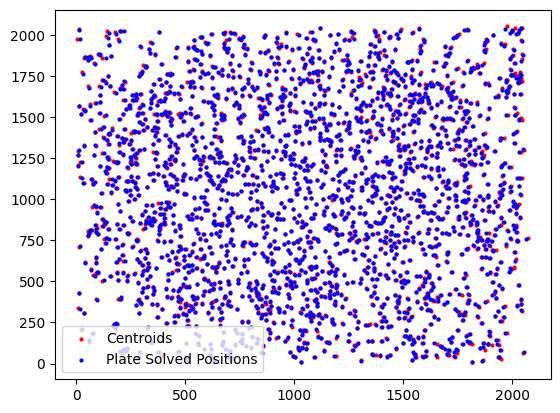

In [15]:
alpha = np.deg2rad(usno_reduced['RAJ2000'])
delta = np.deg2rad(usno_reduced['DEJ2000'])
alpha_0 = cof.ra.rad
delta_0 = cof.dec.rad
X = -(np.cos(delta)*np.sin(alpha - alpha_0))/((np.cos(delta_0))*np.cos(delta)*np.cos(alpha-alpha_0)+np.sin(delta)*np.sin(delta_0))
Y = -(np.sin(delta_0)*np.cos(delta)*np.cos(alpha-alpha_0)-np.cos(delta_0)*np.sin(delta))/(np.cos(delta_0)*np.cos(delta)*np.cos(alpha-alpha_0)+np.sin(delta)*np.sin(delta_0))

# Solve for plate constants
a_x = usno_reduced['x_centroid']
a_y = usno_reduced['y_centroid']
col1 = np.array((focal_length/pixel_size)*X)
col2 = np.array((focal_length/pixel_size)*Y)
col3 = np.ones_like(col1)
B = np.column_stack((col1, col2, col3))
c_x = np.linalg.lstsq(B, a_x, rcond=None)[0]
c_y = np.linalg.lstsq(B, a_y, rcond=None)[0]

# x_lstsq = c_x[0]*col1 +c_x[1]*col2 + c_x[2]
# y_lstsq = c_y[0]*col1 +c_y[1]*col2 + c_y[2]
f_p = focal_length/pixel_size
T = np.column_stack([[f_p*c_x[0], f_p*c_x[1], c_x[2]], [f_p*c_y[0], f_p*c_y[1], c_y[2]], [0, 0, 1]]).T

X_vec = np.array([X,Y,np.ones_like(X)])
x_lstsq = T[0][0]*X + T[0][1]*Y + T[0][2]
y_lstsq = T[1][0]*X + T[1][1]*Y + T[1][2]

usno_reduced['x_lstsq'] = x_lstsq
usno_reduced['y_lstsq'] = y_lstsq

plt.scatter(usno_reduced['y_centroid'], usno_reduced['x_centroid'], s=4, color='red', label='Centroids')
plt.scatter(usno_reduced['y_lstsq'], usno_reduced['x_lstsq'], s=4, color='blue', label='Plate Solved Positions')
plt.legend(loc='best')


In [16]:
usno_reduced.to_csv('usno_reduced.csv', index=False)

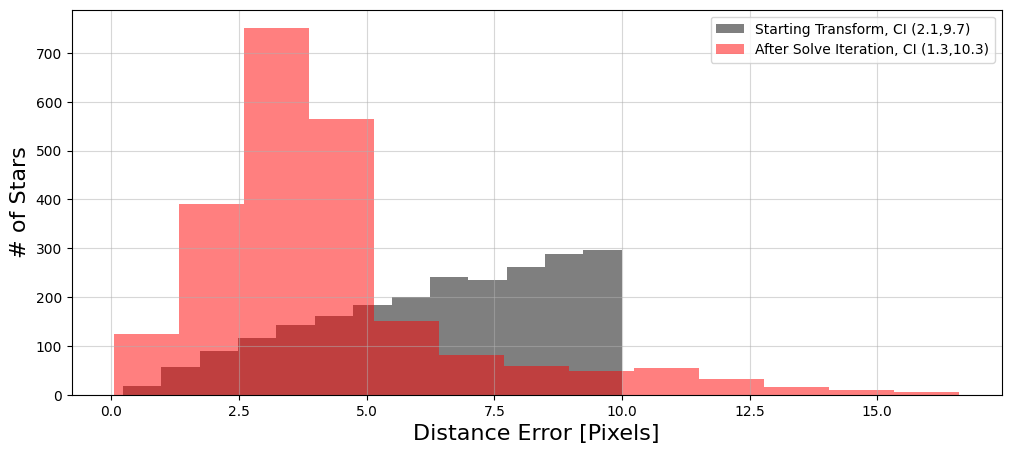

In [17]:
usno_x_approx = np.array(usno_reduced['approx_x'])
usno_y_approx = np.array(usno_reduced['approx_y'])
ccd_x = np.array(usno_reduced['x_centroid'])
ccd_y = np.array(usno_reduced['y_centroid'])
usno_x = np.array(usno_reduced['x_lstsq'])
usno_y = np.array(usno_reduced['y_lstsq'])

def distance(x1,y1,x2,y2):
    return np.sqrt((x1-x2)**2+(y1-y2)**2)

min_dists_before = np.empty_like(usno_x)
min_dists_after = np.empty_like(usno_x)
usno_x_approx = np.array(usno_reduced['approx_x'])

for i in range(usno_x.size):
    min_dists_before[i] = np.min(distance(usno_x_approx[i], usno_y_approx[i], ccd_x, ccd_y))
    min_dists_after[i] = np.min(distance(usno_x[i], usno_y[i], ccd_x, ccd_y))

CI_b = (np.percentile(min_dists_before,5), 
      np.percentile(min_dists_before,95))
CI_a = (np.percentile(min_dists_after,5), 
      np.percentile(min_dists_after,95))

plt.figure(figsize=(12,5))
plt.hist(min_dists_before, 
         bins = "sturges", 
         color = 'k',
         alpha = 0.5, 
         label=f'Starting Transform, CI ({CI_b[0]:.1f},{CI_b[1]:.1f})')
plt.hist(min_dists_after, 
         bins = "sturges", 
         color = 'r',
         alpha = 0.5, 
         label =f'After Solve Iteration, CI ({CI_a[0]:.1f},{CI_a[1]:.1f})')
plt.grid(alpha=0.5)
plt.xlabel("Distance Error [Pixels]", size = 16)
plt.ylabel("# of Stars", size = 16)
plt.legend()
plt.show()

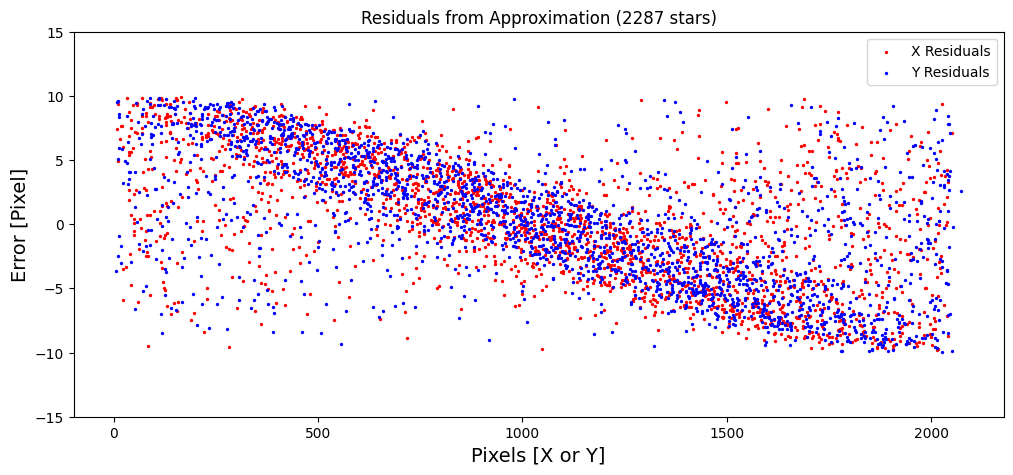

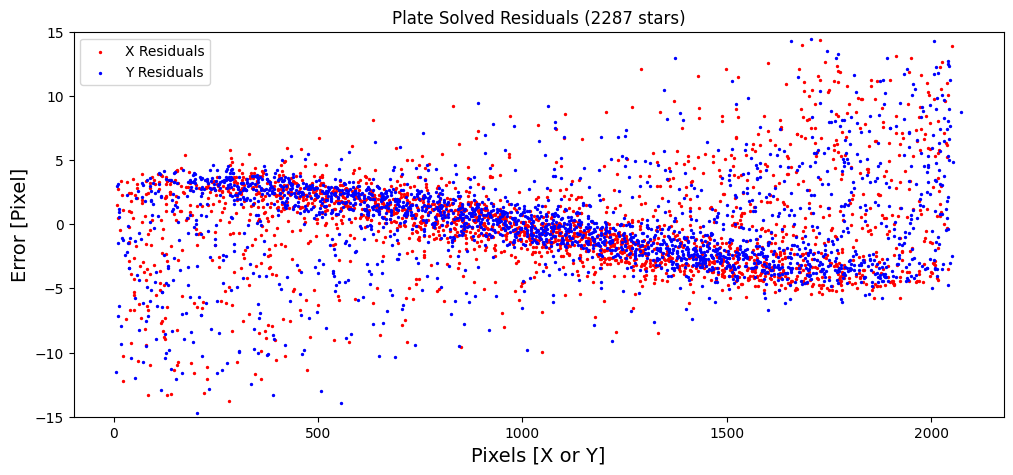

In [18]:
# Plot residuals
plt.figure(figsize=(12,5))
plt.title(f"Residuals from Approximation ({len(usno_reduced)} stars)")
plt.xlabel("Pixels [X or Y]", fontsize=14)
plt.ylabel("Error [Pixel]", fontsize = 14)
plt.scatter(usno_reduced['x_centroid'], usno_reduced['x_centroid'] - usno_reduced['approx_x'], s=2, color='red', label='X Residuals')
plt.scatter(usno_reduced['y_centroid'], usno_reduced['y_centroid'] - usno_reduced['approx_y'], s=2, color='blue', label='Y Residuals')
plt.legend(loc='best')
plt.ylim(-15,15)
plt.show()

plt.figure(figsize=(12,5))
plt.title(f"Plate Solved Residuals ({len(usno_reduced)} stars)")
plt.xlabel("Pixels [X or Y]", fontsize = 14)
plt.ylabel("Error [Pixel]", fontsize = 14)
plt.scatter(usno_reduced['x_centroid'], usno_reduced['x_centroid'] - usno_reduced['x_lstsq'], s=2, color='red', label='X Residuals')
plt.scatter(usno_reduced['y_centroid'], usno_reduced['y_centroid'] - usno_reduced['y_lstsq'], s=2, color='blue', label='Y Residuals')
plt.ylim(-15,15)
plt.legend(loc='best')

# Add residuals to dataframe
usno_reduced['x_residual'] = usno_reduced['x_centroid'] - usno_reduced['x_lstsq']
usno_reduced['y_residual'] = usno_reduced['y_centroid'] - usno_reduced['y_lstsq']

# Filter final stars by x and y residuals
residual_threshold = 2 # pixels
final_stars = usno_reduced[(np.abs(usno_reduced['x_residual']) < residual_threshold) & (np.abs(usno_reduced['y_residual']) < residual_threshold)]

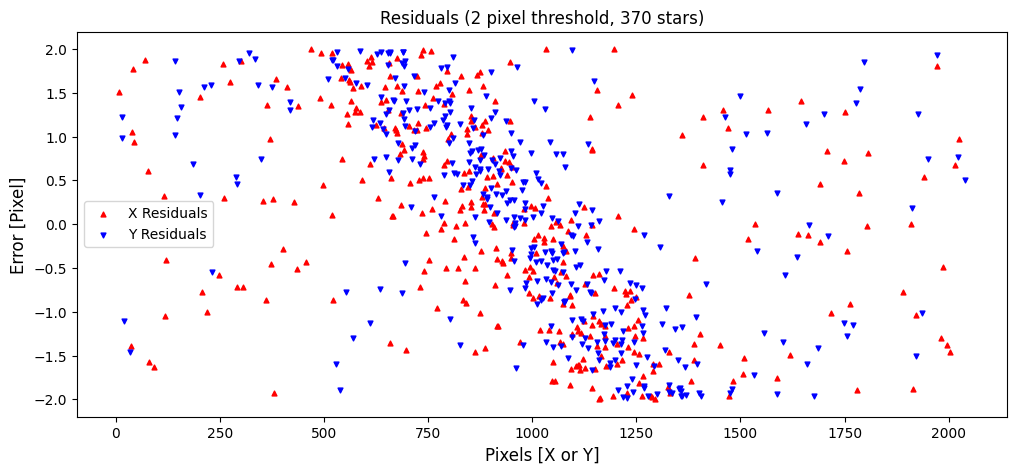

In [19]:
# Plot final residuals
total_matched_stars = len(final_stars)
plt.figure(figsize=(12,5))
plt.title(f"Residuals ({residual_threshold} pixel threshold, {total_matched_stars} stars)".format(t=total_matched_stars))
plt.scatter(final_stars['x_centroid'], final_stars['x_residual'], s=12, color='red', label='X Residuals', marker = '^')
plt.scatter(final_stars['y_centroid'], final_stars['y_residual'], s=12, color='blue', label='Y Residuals', marker = 'v')
plt.xlabel("Pixels [X or Y]", fontsize = 12)
plt.ylabel("Error [Pixel]", fontsize = 12)
plt.legend(loc='best')
plt.grid('')
plt.show()

Now to deal with proserpina. First converting approximate locations from tutorial to pixel space.

In [24]:
# alpha = np.deg2rad(usno_reduced['RAJ2000'])
# delta = np.deg2rad(usno_reduced['DEJ2000'])
# alpha_0 = cof.ra.rad
# delta_0 = cof.dec.rad
# X = -(np.cos(delta)*np.sin(alpha - alpha_0))/((np.cos(delta_0))*np.cos(delta)*np.cos(alpha-alpha_0)+np.sin(delta)*np.sin(delta_0))
# Y = -(np.sin(delta_0)*np.cos(delta)*np.cos(alpha-alpha_0)-np.cos(delta_0)*np.sin(delta))/(np.cos(delta_0)*np.cos(delta)*np.cos(alpha-alpha_0)+np.sin(delta)*np.sin(delta_0))

# # Solve for plate constants
# a_x = usno_reduced['x_centroid']
# a_y = usno_reduced['y_centroid']
# col1 = np.array((focal_length/pixel_size)*X)
# col2 = np.array((focal_length/pixel_size)*Y)
# col3 = np.ones_like(col1)
# B = np.column_stack((col1, col2, col3))
# c_x = np.linalg.lstsq(B, a_x, rcond=None)[0]
# c_y = np.linalg.lstsq(B, a_y, rcond=None)[0]

# x_lstsq = c_x[0]*col1 +c_x[1]*col2 + c_x[2]
# y_lstsq = c_y[0]*col1 +c_y[1]*col2 + c_y[2]

def RADec_pixel(coordinate, center_field):
    alpha = coordinate.ra.rad
    delta = coordinate.dec.rad  
    alpha_0 = center_field.ra.rad
    delta_0 = center_field.dec.rad
    X = -(np.cos(delta)*np.sin(alpha - alpha_0))/((np.cos(delta_0))*np.cos(delta)*np.cos(alpha-alpha_0)+np.sin(delta)*np.sin(delta_0))
    Y = -(np.sin(delta_0)*np.cos(delta)*np.cos(alpha-alpha_0)-np.cos(delta_0)*np.sin(delta))/(np.cos(delta_0)*np.cos(delta)*np.cos(alpha-alpha_0)+np.sin(delta)*np.sin(delta_0))
    x = T[0][0]*X + T[0][1]*Y + T[0][2]
    y = T[1][0]*X + T[1][1]*Y + T[1][2]
    return x, y

emphemeris = [("05:24:07.02",  "26:58:50.6"), 
              ("05:23:33.34",   "26:58:06.3"), 
              ("05:22:30.44",   "26:56:35.2"), 
              ("05:21:14.46",   "26:54:26.4")]

testcoord = coord.SkyCoord(80.834498, 26.949506, unit=(u.deg, u.deg), equinox='J2000')

print(RADec_pixel(testcoord, cof))

coord1 = coord.SkyCoord(emphemeris[0][0], emphemeris[0][1], unit=(u.hourangle, u.deg), equinox='J2000')
coord2 = coord.SkyCoord(emphemeris[1][0], emphemeris[1][1], unit=(u.hourangle, u.deg), equinox='J2000')
coord3 = coord.SkyCoord(emphemeris[2][0], emphemeris[2][1], unit=(u.hourangle, u.deg), equinox='J2000')
coord4 = coord.SkyCoord(emphemeris[3][0], emphemeris[3][1], unit=(u.hourangle, u.deg), equinox='J2000')

# Convert coordinates to pixel space
coord1_cof = coord.SkyCoord(header(astroids[0])['CRVAL1'], header(astroids[0])['CRVAL2'], unit=(u.deg, u.deg), equinox='J2000')
coord2_cof = coord.SkyCoord(header(astroids[1])['CRVAL1'], header(astroids[1])['CRVAL2'], unit=(u.deg, u.deg), equinox='J2000')
coord3_cof = coord.SkyCoord(header(astroids[2])['CRVAL1'], header(astroids[2])['CRVAL2'], unit=(u.deg, u.deg), equinox='J2000')
coord4_cof = coord.SkyCoord(header(astroids[3])['CRVAL1'], header(astroids[3])['CRVAL2'], unit=(u.deg, u.deg), equinox='J2000')

coord1x, coord1y = RADec_pixel(coord1, coord1_cof)
coord2x, coord2y = RADec_pixel(coord2, coord2_cof)
coord3x, coord3y = RADec_pixel(coord3, coord3_cof)
coord4x, coord4y = RADec_pixel(coord4, coord4_cof)

print(f"Day 1 RA DEC: {coord1.ra.deg, coord1.dec.deg}")
print(f"Day 2 RA DEC: {coord2.ra.deg, coord2.dec.deg}")
print(f"Day 3 RA DEC: {coord3.ra.deg, coord3.dec.deg}")
print(f"Day 4 RA DEC: {coord4.ra.deg, coord4.dec.deg}")

print(f"Day 1: {coord1x, coord1y}")
print(f"Day 2: {coord2x, coord2y}")
print(f"Day 3: {coord3x, coord3y}")
print(f"Day 4: {coord4x, coord4y}")

# Day 1
d1t1 = header(asteroid1[0])['DATE-OBS']
d1t2 = header(asteroid1[1])['DATE-OBS']
d1t3 = header(asteroid1[2])['DATE-OBS']

# Day 2
d2t1 = header(asteroid2[0])['DATE-OBS']
d2t2 = header(asteroid2[1])['DATE-OBS']
d2t3 = header(asteroid2[2])['DATE-OBS']

# Day 3
d3t1 = header(asteroid3[0])['DATE-OBS']
d3t2 = header(asteroid3[1])['DATE-OBS']
d3t3 = header(asteroid3[2])['DATE-OBS']

# Day 4 
d4t1 = header(asteroid4[0])['DATE-OBS']
d4t2 = header(asteroid4[1])['DATE-OBS']
d4t3 = header(asteroid4[2])['DATE-OBS']

timestamps = [d1t1, d1t2, d1t3, d2t1, d2t2, d2t3, d3t1, d3t2, d3t3]

print(d1t1,d2t1,d3t1,d4t1)

(950.5330860123541, 429.0525800413093)
Day 1 RA DEC: (81.02924999999999, 26.98072222222222)
Day 2 RA DEC: (80.88891666666666, 26.968416666666666)
Day 3 RA DEC: (80.62683333333332, 26.94311111111111)
Day 4 RA DEC: (80.31024999999998, 26.90733333333333)
Day 1: (1042.888209541402, 1009.0627850474971)
Day 2: (1008.5242499615761, 595.5437486741919)
Day 3: (940.9998225548609, -167.37106186499068)
Day 4: (838.6736903556185, -706.274479709356)
2012-01-20T07:27:54 2012-01-21T07:39:37 2012-01-23T08:35:52 2012-01-26T05:05:05


Day 1 centroid: (1009.0627850474971, 1042.888209541402)
Day 2 centroid: (595.5437486741919, 1008.5242499615761)
Day 3 centroid: (-167.37106186499068, 940.9998225548609)
Day 4 centroid: (-706.274479709356, 838.6736903556185)


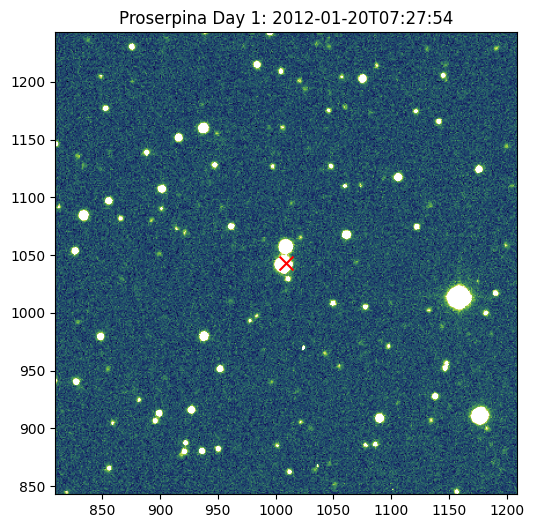

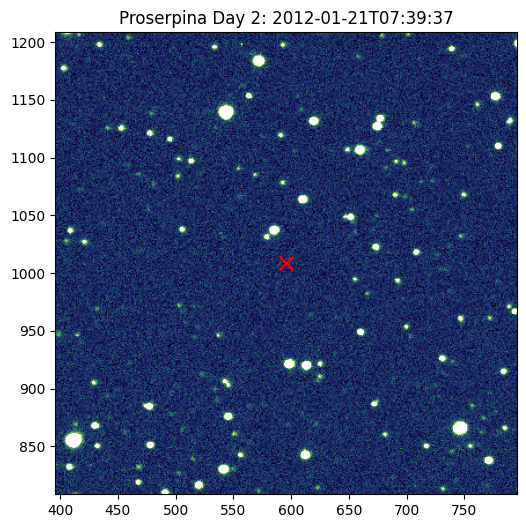

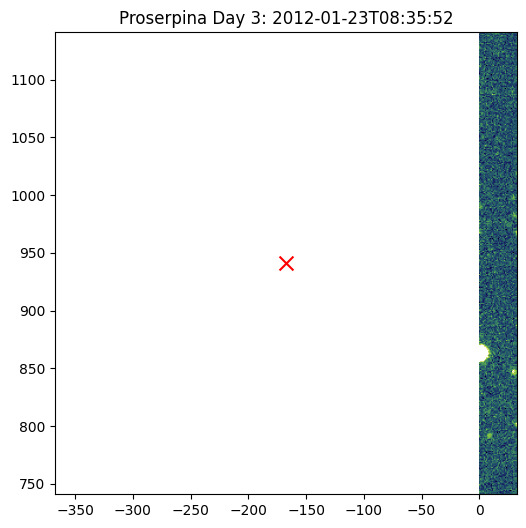

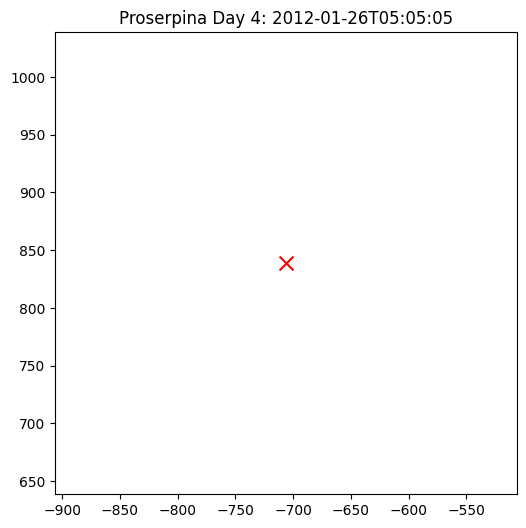

In [25]:
# Centroiding proserpina
box = 200
# x1, y1 = star_gaussian_single_coord([coord1x,coord1y], science_imgs[0])
# x2, y2 = star_gaussian_single_coord([coord2x,coord2y], science_imgs[3])
# x3, y3 = star_gaussian_single_coord([coord3x,coord3y], science_imgs[6])
# x4, y4 = star_gaussian_single_coord([coord4x,coord4y], science_imgs[9])

y1, x1 = coord1x, coord1y
y2, x2 = coord2x, coord2y
y3, x3 = coord3x, coord3y
y4, x4 = coord4x, coord4y

print(f'Day 1 centroid: {x1, y1}')
print(f'Day 2 centroid: {x2, y2}')
print(f'Day 3 centroid: {x3, y3}')
print(f'Day 4 centroid: {x4, y4}')

vmin, max = ZScaleInterval().get_limits(science_imgs[0])

# Day 1 
fig = plt.figure(figsize=(12, 6))
plt.title(f"Proserpina Day 1: {d1t1}")
plt.imshow(science_imgs[0], cmap='cma:lacerta', origin='lower', vmin=vmin, vmax=max)
plt.scatter(x1, y1, marker='x', color='red', s=100, label='Centroid 1')
plt.xlim(x1-box, x1+box)
plt.ylim(y1-box, y1+box)
plt.show()
# Day 2
fig = plt.figure(figsize=(12, 6))
plt.title(f"Proserpina Day 2: {d2t1}")
plt.imshow(science_imgs[3], cmap='cma:lacerta', origin='lower', vmin=vmin, vmax=max)
plt.scatter(x2, y2, marker='x', color='red', s=100, label='Centroid 2')
plt.xlim(x2-box, x2+box)
plt.ylim(y2-box, y2+box)
plt.show()

# Day 3
fig = plt.figure(figsize=(12, 6))
plt.title(f"Proserpina Day 3: {d3t1}")
plt.imshow(science_imgs[6], cmap='cma:lacerta', origin='lower', vmin=vmin, vmax=max)
plt.scatter(x3, y3, marker='x', color='red', s=100, label='Centroid 3')
plt.xlim(x3-box, x3+box)
plt.ylim(y3-box, y3+box)
plt.show()

# Day 4
fig = plt.figure(figsize=(12, 6))
plt.title(f"Proserpina Day 4: {d4t1}")
plt.imshow(science_imgs[9], cmap='cma:lacerta', origin='lower', vmin=vmin, vmax=max)
plt.scatter(x4, y4, marker='x', color='red', s=100, label='Centroid 4')
plt.xlim(x4-box, x4+box)
plt.ylim(y4-box, y4+box)
plt.show()
